# Clustering Track — Obesity Levels Dataset
### 23CSE301 Machine Learning Capstone — Review 2

**Dataset:** `ObesityDataSet_raw_and_data_sinthetic.csv` (eating habits and physical condition of individuals; 2,111 rows, 17 columns)
**Goal:** Discover natural groupings of individuals from lifestyle and body measurements **without using labels during fitting**. The ground-truth column `NObeyesdad` is held aside and used *only* afterwards to interpret/validate the clusters.

This notebook covers:
- **Section A** — Dataset & EDA
- **Section B** — Preprocessing (clustering-appropriate: no train/test split, no label in the feature matrix)
- **Section C** — Clustering Track: K-Means and Agglomerative Hierarchical Clustering
  - Evaluation: Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index
  - Elbow curve (K-Means), Dendrogram + linkage comparison (Hierarchical)
  - Visualisation: PCA 2-D for every algorithm, t-SNE for both algorithms
- **Section D** — Post-hoc validation against `NObeyesdad`, cluster profiling, conclusion

## Section A — Dataset & EDA

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
palette = sns.color_palette('colorblind')

RANDOM_STATE = 42
DATA_PATH = 'ObesityDataSet_raw_and_data_sinthetic.csv'

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 2111 rows x 17 columns


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
print("Column dtypes:")
print(df.dtypes)

Column dtypes:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object


In [4]:
missing = df.isnull().sum()
print("Total missing values:", missing.sum())
print("Duplicate rows:", df.duplicated().sum())
df['NObeyesdad'].value_counts().to_frame('count').assign(percent=lambda d: (d['count']/len(df)*100).round(2))

Total missing values: 0
Duplicate rows: 24


,count,percent
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


**Observation (A1):** The dataset has 2,111 rows and 17 columns (8 numeric, 8 categorical features plus the `NObeyesdad` label) with **no missing values**. There are **24 exact duplicate rows**, which are removed in Section B. The seven obesity classes are almost perfectly balanced (12.9%-16.6% each), which is a hint that much of the data is synthetic (SMOTE-generated, as the file name says): about 65% of `Age` values and 39% of `FCVC` values are non-integers even though they are naturally whole numbers. This matters for clustering because synthetic points are interpolations between real ones, so they can blur the boundaries between groups.

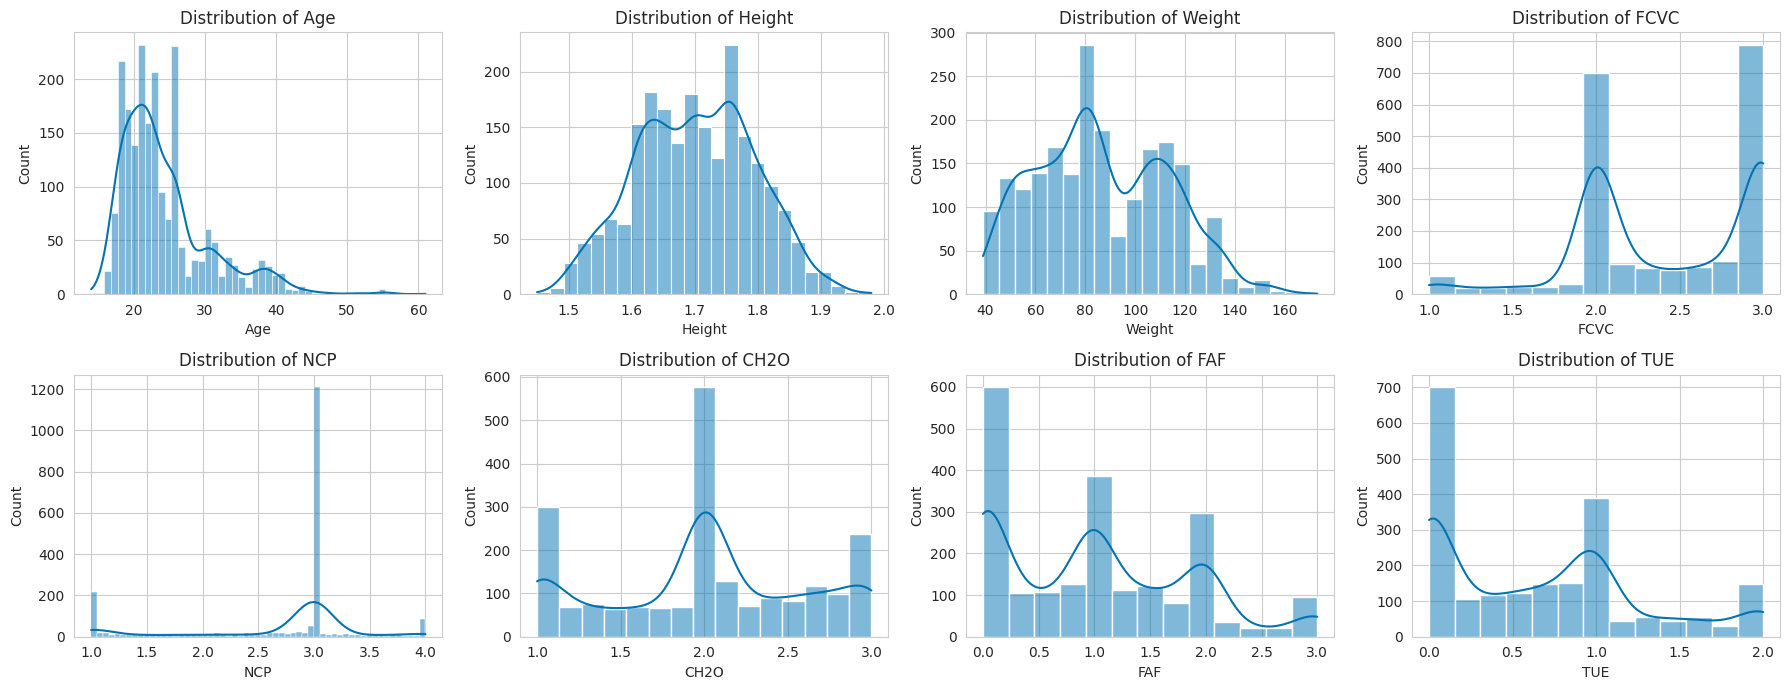

In [5]:
numeric_cols = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color=palette[0])
    ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()

**Observation:** `Age` is strongly right-skewed (skewness ≈ 1.5): most people are in their early-to-mid 20s with a thin tail up to 61. `NCP` (number of main meals) is left-skewed (≈ -1.1) with most people reporting 3 meals, and `TUE` and `FAF` are right-skewed. `Height` is almost symmetric and `Weight` is broad (about 40-173 kg). Because the features sit on very different scales (kg vs. 0-3 survey scores), they must be standardised before any distance-based clustering.

#### Categorical feature distributions

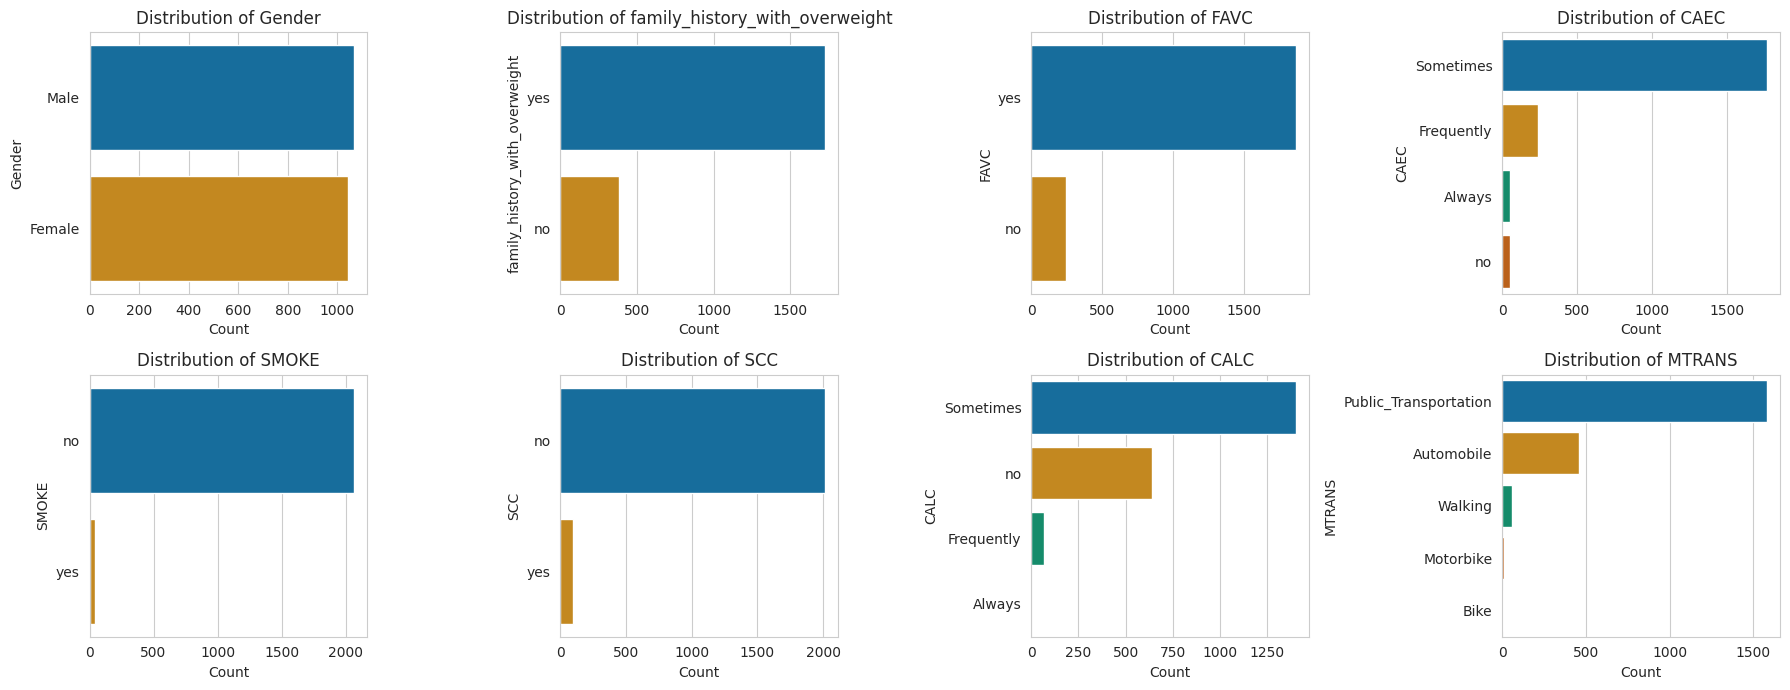

In [6]:
categorical_cols = ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flatten(), categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, palette=palette, ax=ax)
    ax.set_title(f'Distribution of {col}'); ax.set_xlabel('Count')
plt.tight_layout(); plt.show()

**Observation:** Gender is split almost evenly (50.6% male). Several categoricals are dominated by one level: 88% report high-calorie food (`FAVC` = yes), 82% have a family history of overweight, 98% do not smoke, 95% do not monitor calories (`SCC` = no), 84% eat between meals only 'Sometimes', and 75% use public transport. Near-constant features such as `SMOKE` carry little structure, so they will contribute almost nothing to cluster separation, while `CALC`, `CAEC` and `MTRANS` have more even splits.